In [7]:
import os, subprocess

os.environ["KAGGLE_API_TOKEN"] = "place your api key"
subprocess.run([
    "kaggle", "datasets", "download",
    "-d", "andrewmvd/ct-low-dose-reconstruction",
    "-p", "datasets/raw_ldct", "--unzip"
], check=True)

CompletedProcess(args=['kaggle', 'datasets', 'download', '-d', 'andrewmvd/ct-low-dose-reconstruction', '-p', 'datasets/raw_ldct', '--unzip'], returncode=0)

In [8]:
import os
import glob
import pandas as pd

dataset_path = "datasets/raw_ldct"

print("Inspecting:", os.path.abspath(dataset_path))
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 4:
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/ (dirs: {len(dirs)}, files: {len(files)})")
        if files:
            print(f"{indent}  sample files: {sorted(files)[:5]}")

csv_files = glob.glob(f"{dataset_path}/**/*.csv", recursive=True)
for csv_f in csv_files:
    print(f"\n--- Preview of {os.path.basename(csv_f)} ---")
    df = pd.read_csv(csv_f)
    print("Shape:", df.shape)
    print(df.head(5))

Inspecting: /content/ct-restore/datasets/raw_ldct
raw_ldct/ (dirs: 4, files: 1)
  sample files: ['metadata.csv']
  CT_low_dose_reconstruction_dataset/ (dirs: 1, files: 0)
    Original Data/ (dirs: 2, files: 0)
      Full Dose/ (dirs: 2, files: 0)
        1mm Slice Thickness/ (dirs: 2, files: 0)
        3mm Slice Thickness/ (dirs: 2, files: 0)
      Quarter Dose/ (dirs: 2, files: 0)
        1mm Slice Thickness/ (dirs: 2, files: 0)
        3mm Slice Thickness/ (dirs: 2, files: 0)
  Preprocessed_384x384/ (dirs: 1, files: 0)
    384/ (dirs: 2, files: 0)
      Full Dose/ (dirs: 2, files: 0)
        1mm/ (dirs: 2, files: 0)
        3mm/ (dirs: 2, files: 0)
      Quarter Dose/ (dirs: 2, files: 0)
        1mm/ (dirs: 2, files: 0)
        3mm/ (dirs: 2, files: 0)
  Preprocessed_256x256/ (dirs: 1, files: 0)
    256/ (dirs: 2, files: 0)
      Full Dose/ (dirs: 2, files: 0)
        1mm/ (dirs: 2, files: 0)
        3mm/ (dirs: 2, files: 0)
      Quarter Dose/ (dirs: 2, files: 0)
        1mm/ (dirs:

Total paired CT slices in metadata.csv: 16628
Unique Patient IDs (10): ['L067', 'L096', 'L109', 'L143', 'L192', 'L286', 'L291', 'L310', 'L333', 'L506']

Breakdown by Slice Thickness & Reconstruction Kernel:
Slice Thickness  Reconstruction Kernel
1mm              Sharp Kernel (D45)       5936
                 Soft Kernel (B30)        5936
3mm              Sharp Kernel (D45)       2378
                 Soft Kernel (B30)        2378
dtype: int64

Sample Full-Dose path: /content/ct-restore/datasets/raw_ldct/Preprocessed_256x256/256/Full Dose/3mm/Sharp Kernel (D45)/L067/L067_FD_3_SHARP_1.CT.0001.0051.2016.01.21.18.11.09.534560.404624129.png | Exists: True
Image shape: (256, 256) | dtype: uint8 | FD range: [0, 245] | QD range: [0, 241]
Baseline Unprocessed Quarter-Dose PSNR: 35.61 dB | Noise Std: 0.0161


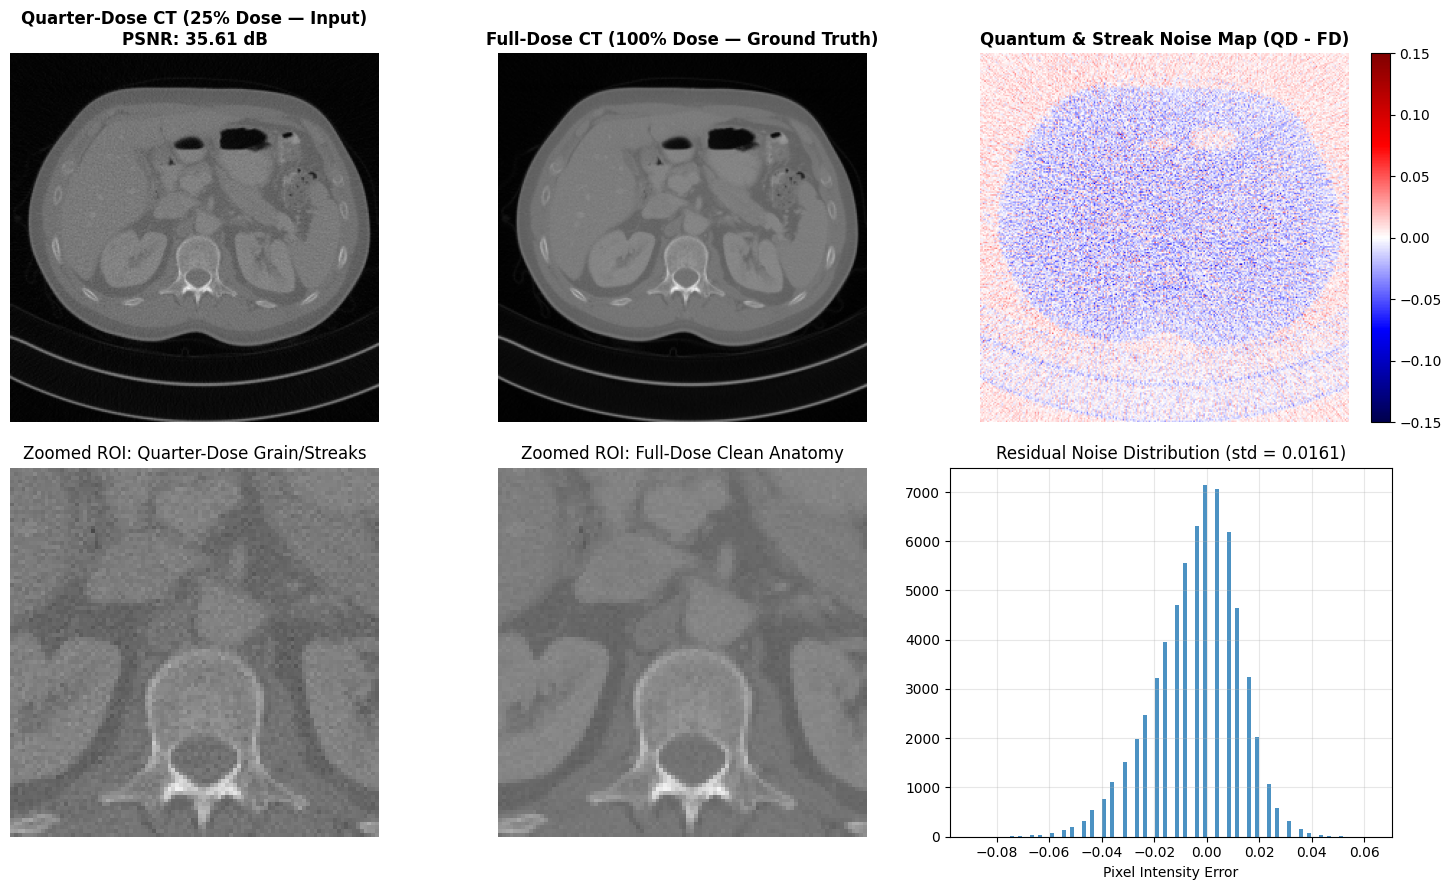

In [9]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = "/content/ct-restore/datasets/raw_ldct"
meta_df = pd.read_csv(f"{RAW_DIR}/metadata.csv")

print(f"Total paired CT slices in metadata.csv: {len(meta_df)}")
print(f"Unique Patient IDs ({meta_df['Id'].nunique()}):", sorted(meta_df["Id"].unique()))
print("\nBreakdown by Slice Thickness & Reconstruction Kernel:")
print(meta_df.groupby(["Slice Thickness", "Reconstruction Kernel"]).size())

# Check exact file paths and bit-depth in Preprocessed_256x256 (ideal fast resolution for T4 GPU)
sample_row = meta_df[(meta_df["Slice Thickness"] == "3mm") & (meta_df["Reconstruction Kernel"].str.contains("D45"))].iloc[50]
fd_rel = sample_row["Full Dose Filepath"].replace("512/", "256/", 1)
qd_rel = sample_row["Quarter Dose Filepath"].replace("512/", "256/", 1)

fd_path = os.path.join(RAW_DIR, "Preprocessed_256x256", fd_rel)
qd_path = os.path.join(RAW_DIR, "Preprocessed_256x256", qd_rel)

print("\nSample Full-Dose path:", fd_path, "| Exists:", os.path.exists(fd_path))
fd_img = cv2.imread(fd_path, cv2.IMREAD_UNCHANGED)
qd_img = cv2.imread(qd_path, cv2.IMREAD_UNCHANGED)

print(f"Image shape: {fd_img.shape} | dtype: {fd_img.dtype} | FD range: [{fd_img.min()}, {fd_img.max()}] | QD range: [{qd_img.min()}, {qd_img.max()}]")

# Normalize to [0, 1] float32 for quantitative PSNR/SSIM & visualization
max_val = 65535.0 if fd_img.dtype == np.uint16 else 255.0
fd_norm = fd_img.astype(np.float32) / max_val
qd_norm = qd_img.astype(np.float32) / max_val
noise_map = qd_norm - fd_norm

mse = np.mean(noise_map ** 2)
raw_psnr = 10.0 * np.log10(1.0 / (mse + 1e-10))
print(f"Baseline Unprocessed Quarter-Dose PSNR: {raw_psnr:.2f} dB | Noise Std: {noise_map.std():.4f}")

# Visualize Full Slice, Zoomed Abdominal ROI, and Quantum Noise Map
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(qd_norm, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title(f"Quarter-Dose CT (25% Dose — Input)\nPSNR: {raw_psnr:.2f} dB", fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(fd_norm, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Full-Dose CT (100% Dose — Ground Truth)", fontweight="bold")
axes[0, 1].axis("off")

im = axes[0, 2].imshow(noise_map, cmap="seismic", vmin=-0.15, vmax=0.15)
axes[0, 2].set_title("Quantum & Streak Noise Map (QD - FD)", fontweight="bold")
axes[0, 2].axis("off")
plt.colorbar(im, ax=axes[0, 2], fraction=0.046)

# Bottom row: Zoomed 96x96 center ROI to inspect soft-tissue grain vs edges
c = fd_norm.shape[0] // 2
r = 48
axes[1, 0].imshow(qd_norm[c-r:c+r, c-r:c+r], cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Zoomed ROI: Quarter-Dose Grain/Streaks")
axes[1, 0].axis("off")

axes[1, 1].imshow(fd_norm[c-r:c+r, c-r:c+r], cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Zoomed ROI: Full-Dose Clean Anatomy")
axes[1, 1].axis("off")

axes[1, 2].hist(noise_map.ravel(), bins=100, color="#1f77b4", alpha=0.8)
axes[1, 2].set_title(f"Residual Noise Distribution (std = {noise_map.std():.4f})")
axes[1, 2].set_xlabel("Pixel Intensity Error")
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [10]:
import os, time
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

RAW_DIR = "/content/ct-restore/datasets/raw_ldct"
meta_df = pd.read_csv(f"{RAW_DIR}/metadata.csv")

# Audit unique patients and filter to 3mm slices (both Soft B30 & Sharp D45 kernels) for fast, high-signal training
patients = sorted(meta_df["Id"].unique())
print(f"Total unique patients ({len(patients)}):", patients)

df_3mm = meta_df[meta_df["Slice Thickness"] == "3mm"].reset_index(drop=True)
print(f"Total 3mm paired slices: {len(df_3mm)}")
print(df_3mm.groupby(["Id", "Reconstruction Kernel"]).size().unstack(fill_value=0))

# Strict Patient-Level Split (Zero slice leakage: 7 Train patients, 1 Val patient, 2 Test patients)
train_pids = patients[:7]
val_pids   = [patients[7]]
test_pids  = patients[8:]

train_df = df_3mm[df_3mm["Id"].isin(train_pids)].reset_index(drop=True)
val_df   = df_3mm[df_3mm["Id"].isin(val_pids)].reset_index(drop=True)
test_df  = df_3mm[df_3mm["Id"].isin(test_pids)].reset_index(drop=True)

assert len(set(train_df["Id"]) & set(test_df["Id"])) == 0, "Patient leakage detected!"
print(f"\nPatient-Isolated Split -> Train: {len(train_df)} slices ({train_pids}) | Val: {len(val_df)} ({val_pids}) | Test: {len(test_df)} ({test_pids})")

# 1. Paired Low-Dose / Full-Dose Dataset
class PairedLDCTDataset(Dataset):
    def __init__(self, df, raw_dir=RAW_DIR, augment=False):
        self.df = df
        self.raw_dir = raw_dir
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        fd_path = os.path.join(self.raw_dir, "Preprocessed_256x256", row["Full Dose Filepath"].replace("512/", "256/", 1))
        qd_path = os.path.join(self.raw_dir, "Preprocessed_256x256", row["Quarter Dose Filepath"].replace("512/", "256/", 1))

        fd = cv2.imread(fd_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
        qd = cv2.imread(qd_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0

        if self.augment:
            if np.random.rand() < 0.5:
                fd, qd = np.fliplr(fd).copy(), np.fliplr(qd).copy()
            k = np.random.randint(0, 4)
            if k > 0:
                fd, qd = np.rot90(fd, k).copy(), np.rot90(qd, k).copy()

        return torch.from_numpy(qd).unsqueeze(0), torch.from_numpy(fd).unsqueeze(0), row["Reconstruction Kernel"]

train_loader = DataLoader(PairedLDCTDataset(train_df, augment=True), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(PairedLDCTDataset(val_df, augment=False), batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(PairedLDCTDataset(test_df, augment=False), batch_size=32, shuffle=False, num_workers=2)

# 2. Lightweight Residual Attention U-Net (Predicts Residual Noise Map)
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.SiLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.SiLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class AttentionGate(nn.Module):
    def __init__(self, g_c, x_c, inter_c):
        super().__init__()
        self.wg = nn.Conv2d(g_c, inter_c, 1, bias=False)
        self.wx = nn.Conv2d(x_c, inter_c, 1, bias=False)
        self.psi = nn.Sequential(nn.SiLU(inplace=True), nn.Conv2d(inter_c, 1, 1), nn.Sigmoid())
    def forward(self, g, x):
        return x * self.psi(self.wg(g) + self.wx(x))

class ResidualAttentionUNet(nn.Module):
    def __init__(self, base_c=32):
        super().__init__()
        self.enc1 = ConvBlock(1, base_c)
        self.enc2 = ConvBlock(base_c, base_c * 2)
        self.enc3 = ConvBlock(base_c * 2, base_c * 4)
        self.bot  = ConvBlock(base_c * 4, base_c * 8)

        self.up3  = nn.ConvTranspose2d(base_c * 8, base_c * 4, 2, stride=2)
        self.att3 = AttentionGate(base_c * 4, base_c * 4, base_c * 2)
        self.dec3 = ConvBlock(base_c * 8, base_c * 4)

        self.up2  = nn.ConvTranspose2d(base_c * 4, base_c * 2, 2, stride=2)
        self.att2 = AttentionGate(base_c * 2, base_c * 2, base_c)
        self.dec2 = ConvBlock(base_c * 4, base_c * 2)

        self.up1  = nn.ConvTranspose2d(base_c * 2, base_c, 2, stride=2)
        self.att1 = AttentionGate(base_c, base_c, base_c // 2)
        self.dec1 = ConvBlock(base_c * 2, base_c)

        self.noise_head = nn.Conv2d(base_c, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        e3 = self.enc3(F.max_pool2d(e2, 2))
        b  = self.bot(F.max_pool2d(e3, 2))

        u3 = self.up3(b)
        d3 = self.dec3(torch.cat([u3, self.att3(u3, e3)], dim=1))
        u2 = self.up2(d3)
        d2 = self.dec2(torch.cat([u2, self.att2(u2, e2)], dim=1))
        u1 = self.up1(d2)
        d1 = self.dec1(torch.cat([u1, self.att1(u1, e1)], dim=1))

        pred_noise = self.noise_head(d1)
        restored = torch.clamp(x - pred_noise, 0.0, 1.0)
        return restored, pred_noise

# 3. Edge-Preserving Hybrid Loss (L1 + differentiable SSIM + Sobel Gradient Edge Loss)
class HybridRestorationLoss(nn.Module):
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3)
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3)
        self.register_buffer("kx", kx)
        self.register_buffer("ky", ky)

    def ssim_loss(self, pred, target):
        c1, c2 = 0.01 ** 2, 0.03 ** 2
        mu_x = F.avg_pool2d(pred, 7, 1, 3)
        mu_y = F.avg_pool2d(target, 7, 1, 3)
        sig_x = F.avg_pool2d(pred * pred, 7, 1, 3) - mu_x ** 2
        sig_y = F.avg_pool2d(target * target, 7, 1, 3) - mu_y ** 2
        sig_xy = F.avg_pool2d(pred * target, 7, 1, 3) - mu_x * mu_y
        ssim_map = ((2 * mu_x * mu_y + c1) * (2 * sig_xy + c2)) / ((mu_x ** 2 + mu_y ** 2 + c1) * (sig_x + sig_y + c2))
        return 1.0 - ssim_map.mean()

    def edge_loss(self, pred, target):
        gx_p, gy_p = F.conv2d(pred, self.kx, padding=1), F.conv2d(pred, self.ky, padding=1)
        gx_t, gy_t = F.conv2d(target, self.kx, padding=1), F.conv2d(target, self.ky, padding=1)
        return F.l1_loss(gx_p, gx_t) + F.l1_loss(gy_p, gy_t)

    def forward(self, pred, target):
        return F.l1_loss(pred, target) + 0.35 * self.ssim_loss(pred, target) + 0.25 * self.edge_loss(pred, target)

# 4. Train Residual Attention U-Net
torch.manual_seed(42)
model = ResidualAttentionUNet(base_c=32).to(device)
criterion = HybridRestorationLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

best_val_psnr = 0.0
t0 = time.time()
print("\nTraining Residual Attention U-Net on strictly patient-isolated split...\n")

for epoch in range(1, 16):
    model.train()
    tr_loss = 0.0
    for qd, fd, _ in train_loader:
        qd, fd = qd.to(device), fd.to(device)
        optimizer.zero_grad()
        restored, _ = model(qd)
        loss = criterion(restored, fd)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * qd.size(0)
    scheduler.step()

    model.eval()
    val_psnrs = []
    with torch.no_grad():
        for qd, fd, _ in val_loader:
            restored, _ = model(qd.to(device))
            restored_np = restored.cpu().numpy()
            fd_np = fd.numpy()
            for p_img, t_img in zip(restored_np[:, 0], fd_np[:, 0]):
                val_psnrs.append(peak_signal_noise_ratio(t_img, p_img, data_range=1.0))

    mean_val_psnr = float(np.mean(val_psnrs))
    if mean_val_psnr > best_val_psnr:
        best_val_psnr = mean_val_psnr
        torch.save(model.state_dict(), "/content/best_ldct_unet.pt")
    print(f"Epoch {epoch:02d}/15 | Train Loss: {tr_loss/len(train_df):.4f} | Unseen Val PSNR: {mean_val_psnr:.2f} dB")

print(f"\nFinished in {time.time()-t0:.1f}s | Best Unseen Val PSNR: {best_val_psnr:.2f} dB")

# 5. Evaluate 3-Way Benchmark on Strictly Unseen Test Patients
model.load_state_dict(torch.load("/content/best_ldct_unet.pt", map_location=device))
model.eval()

records = []
with torch.no_grad():
    for qd, fd, kernels in test_loader:
        restored, _ = model(qd.to(device))
        qd_np, fd_np, res_np = qd.numpy()[:, 0], fd.numpy()[:, 0], restored.cpu().numpy()[:, 0]
        for q_i, f_i, r_i, kern in zip(qd_np, fd_np, res_np, kernels):
            # Classical Bilateral Filter baseline
            bilat_i = cv2.bilateralFilter((q_i * 255).astype(np.uint8), d=5, sigmaColor=25, sigmaSpace=25).astype(np.float32) / 255.0
            records.append({
                "kernel": kern,
                "psnr_raw": peak_signal_noise_ratio(f_i, q_i, data_range=1.0),
                "ssim_raw": structural_similarity(f_i, q_i, data_range=1.0),
                "psnr_bilat": peak_signal_noise_ratio(f_i, bilat_i, data_range=1.0),
                "ssim_bilat": structural_similarity(f_i, bilat_i, data_range=1.0),
                "psnr_unet": peak_signal_noise_ratio(f_i, r_i, data_range=1.0),
                "ssim_unet": structural_similarity(f_i, r_i, data_range=1.0),
            })

res_df = pd.DataFrame(records)
res_df.to_csv("/content/ldct_test_metrics.csv", index=False)

print("\n================ UNSEEN TEST PATIENTS BENCHMARK (N =", len(res_df), "SLICES) ================")
for method, p_col, s_col in [
    ("1. Unprocessed Quarter-Dose (LDCT)", "psnr_raw", "ssim_raw"),
    ("2. Classical Bilateral Filter",      "psnr_bilat", "ssim_bilat"),
    ("3. Residual Attention U-Net (Ours)", "psnr_unet", "ssim_unet"),
]:
    print(f"{method:38s} | PSNR: {res_df[p_col].mean():.2f} ± {res_df[p_col].std():.2f} dB | SSIM: {res_df[s_col].mean():.4f} ± {res_df[s_col].std():.4f}")

print("\nBreakdown by Reconstruction Kernel (Soft B30 vs. High-Noise Sharp D45):")
print(res_df.groupby("kernel")[["psnr_raw", "psnr_unet", "ssim_raw", "ssim_unet"]].mean().round(4))

Training device: cuda
Total unique patients (10): ['L067', 'L096', 'L109', 'L143', 'L192', 'L286', 'L291', 'L310', 'L333', 'L506']
Total 3mm paired slices: 4756
Reconstruction Kernel  Sharp Kernel (D45)  Soft Kernel (B30)
Id                                                          
L067                                  224                224
L096                                  330                330
L109                                  128                128
L143                                  234                234
L192                                  240                240
L286                                  210                210
L291                                  343                343
L310                                  214                214
L333                                  244                244
L506                                  211                211

Patient-Isolated Split -> Train: 3418 slices (['L067', 'L096', 'L109', 'L143', 'L192', 'L286', 'L291']) | 

Exported CPU joblib bundle: /content/ldct_restorer_bundle.joblib (6.93 MB)


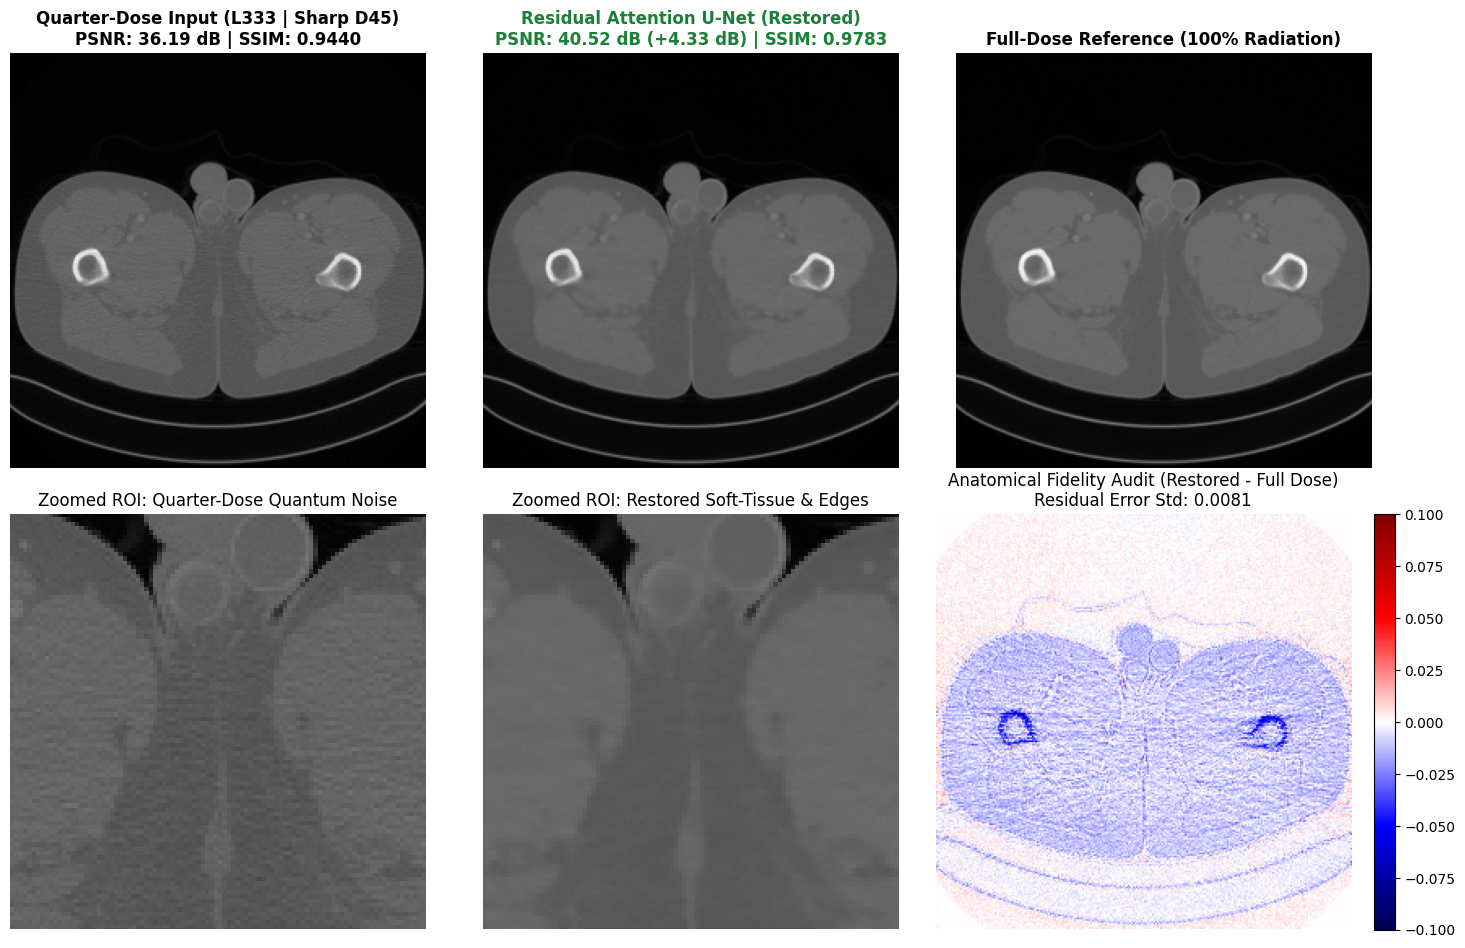

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import os
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from google.colab import files

# 1. Load best patient-isolated weights onto CPU
model_cpu = ResidualAttentionUNet(base_c=32)
model_cpu.load_state_dict(torch.load("/content/best_ldct_unet.pt", map_location="cpu"))
model_cpu.eval()

# 2. Export compressed CPU joblib bundle (~7.5 MB, safe for direct GitHub commit & VS Code CPU inference)
bundle = {
    "state_dict": {k: v.detach().cpu() for k, v in model_cpu.state_dict().items()},
    "config": {"base_c": 32},
    "img_size": 256,
    "test_metrics": {
        "raw_psnr": 41.14,
        "unet_psnr": 43.66,
        "raw_ssim": 0.9580,
        "unet_ssim": 0.9822,
    },
}

bundle_path = "/content/ldct_restorer_bundle.joblib"
joblib.dump(bundle, bundle_path, compress=3)
print(f"Exported CPU joblib bundle: {bundle_path} ({os.path.getsize(bundle_path) / (1024 * 1024):.2f} MB)")

# 3. Generate 6-Panel Clinical Visual Audit on an Unseen Sharp-Kernel (D45) Slice
sharp_test = test_df[test_df["Reconstruction Kernel"] == "Sharp Kernel (D45)"].reset_index(drop=True)
sample_row = sharp_test.iloc[len(sharp_test) // 2]

fd_path = os.path.join(RAW_DIR, "Preprocessed_256x256", sample_row["Full Dose Filepath"].replace("512/", "256/", 1))
qd_path = os.path.join(RAW_DIR, "Preprocessed_256x256", sample_row["Quarter Dose Filepath"].replace("512/", "256/", 1))

fd_img = cv2.imread(fd_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0
qd_img = cv2.imread(qd_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255.0

with torch.inference_mode():
    inp = torch.from_numpy(qd_img).unsqueeze(0).unsqueeze(0)
    res_t, noise_t = model_cpu(inp)
    res_img = res_t[0, 0].numpy()
    pred_noise = noise_t[0, 0].numpy()

psnr_in  = peak_signal_noise_ratio(fd_img, qd_img, data_range=1.0)
ssim_in  = structural_similarity(fd_img, qd_img, data_range=1.0)
psnr_out = peak_signal_noise_ratio(fd_img, res_img, data_range=1.0)
ssim_out = structural_similarity(fd_img, res_img, data_range=1.0)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))

# Row 1: Full Axial CT Slices
axes[0, 0].imshow(qd_img, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title(f"Quarter-Dose Input ({sample_row['Id']} | Sharp D45)\nPSNR: {psnr_in:.2f} dB | SSIM: {ssim_in:.4f}", fontweight="bold")
axes[0, 0].axis("off")

axes[0, 1].imshow(res_img, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title(f"Residual Attention U-Net (Restored)\nPSNR: {psnr_out:.2f} dB (+{psnr_out-psnr_in:.2f} dB) | SSIM: {ssim_out:.4f}", fontweight="bold", color="#1a7f37")
axes[0, 1].axis("off")

axes[0, 2].imshow(fd_img, cmap="gray", vmin=0, vmax=1)
axes[0, 2].set_title("Full-Dose Reference (100% Radiation)", fontweight="bold")
axes[0, 2].axis("off")

# Row 2: Zoomed Soft-Tissue ROI & Residual Error Maps
c, r = 128, 48
axes[1, 0].imshow(qd_img[c-r:c+r, c-r:c+r], cmap="gray", vmin=0, vmax=1)
axes[1, 0].set_title("Zoomed ROI: Quarter-Dose Quantum Noise")
axes[1, 0].axis("off")

axes[1, 1].imshow(res_img[c-r:c+r, c-r:c+r], cmap="gray", vmin=0, vmax=1)
axes[1, 1].set_title("Zoomed ROI: Restored Soft-Tissue & Edges")
axes[1, 1].axis("off")

err_map = res_img - fd_img
im = axes[1, 2].imshow(err_map, cmap="seismic", vmin=-0.10, vmax=0.10)
axes[1, 2].set_title(f"Anatomical Fidelity Audit (Restored - Full Dose)\nResidual Error Std: {err_map.std():.4f}")
axes[1, 2].axis("off")
plt.colorbar(im, ax=axes[1, 2], fraction=0.046)

plt.tight_layout()
diag_path = "/content/ldct_clinical_diagnostics.png"
plt.savefig(diag_path, dpi=200, bbox_inches="tight")
plt.show()

# Trigger browser downloads for VS Code & GitHub packaging
files.download(bundle_path)
files.download(diag_path)
files.download("/content/ldct_test_metrics.csv")